Task 1: Proof

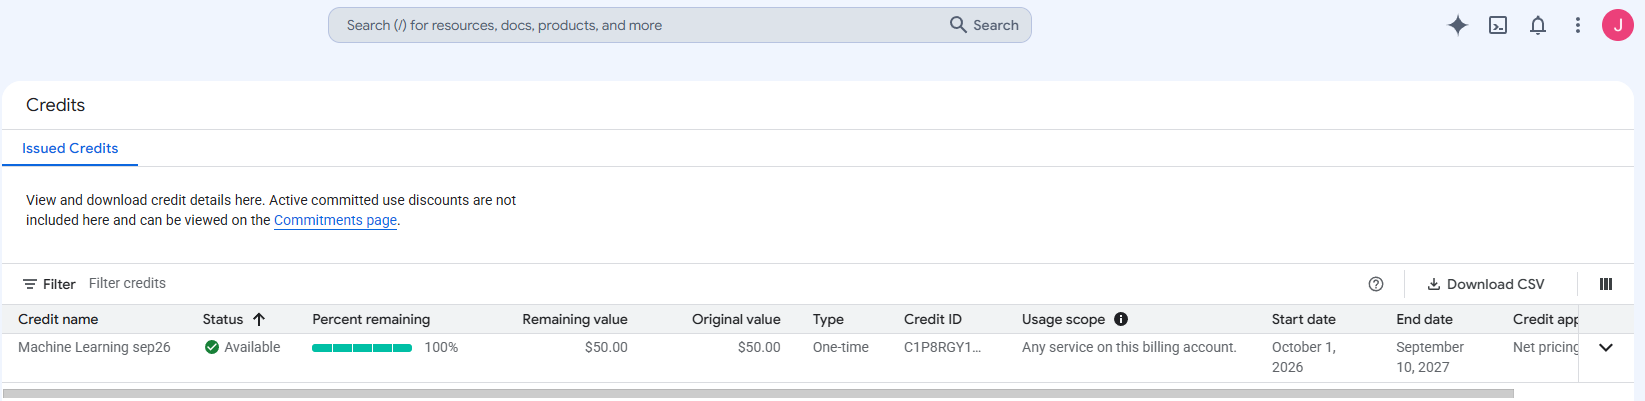

In [ ]:
import platform
import os

print("Hostname:", platform.node())
print("Python version:", platform.python_version())
print("Working directory:", os.getcwd())

Hostname: 3562e57dedf9
Python version: 3.12.13
Working directory: /content


Task 2: Load Data

In [ ]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# I Copied From Website Import Python
air_quality = fetch_ucirepo(id=360)

# data (as pandas dataframes)
X = air_quality.data.features
y = air_quality.data.targets

# metadata
print(air_quality.metadata)

# variable information
print(air_quality.variables)

{'uci_id': 360, 'name': 'Air Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/360/air+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/360/data.csv', 'abstract': 'Contains the responses of a gas multisensor device deployed on the field in an Italian city. Hourly responses averages are recorded along with gas concentrations references from a certified analyzer. ', 'area': 'Computer Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 9358, 'num_features': 15, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2008, 'last_updated': 'Sun Mar 10 2024', 'dataset_doi': '10.24432/C59K5F', 'creators': ['Saverio Vito'], 'intro_paper': {'ID': 420, 'type': 'NATIVE', 'title': 'On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario', 'authors': 

Task 3: Structural Inspection

In [ ]:
df = pd.concat([X, y], axis=1)

display(df.head())
print("=" * 50)
df.info()
print("=" * 50)
display(df.describe().T)

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   int64  
 4   NMHC(GT)       9357 non-null   int64  
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   int64  
 7   NOx(GT)        9357 non-null   int64  
 8   PT08.S3(NOx)   9357 non-null   int64  
 9   NO2(GT)        9357 non-null   int64  
 10  PT08.S4(NO2)   9357 non-null   int64  
 11  PT08.S5(O3)    9357 non-null   int64  
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(5), int64(8), object(2)
memory usage: 1.1+ MB


,count,mean,std,min,25%,50%,75%,max
CO(GT),9357.0,-34.207524,77.657170,-200.0,0.6000,1.5000,2.6000,11.900
PT08.S1(CO),9357.0,1048.990061,329.832710,-200.0,921.0000,1053.0000,1221.0000,2040.000
NMHC(GT),9357.0,-159.090093,139.789093,-200.0,-200.0000,-200.0000,-200.0000,1189.000
C6H6(GT),9357.0,1.865683,41.380206,-200.0,4.0000,7.9000,13.6000,63.700
PT08.S2(NMHC),9357.0,894.595276,342.333252,-200.0,711.0000,895.0000,1105.0000,2214.000
NOx(GT),9357.0,168.616971,257.433866,-200.0,50.0000,141.0000,284.0000,1479.000
PT08.S3(NOx),9357.0,794.990168,321.993552,-200.0,637.0000,794.0000,960.0000,2683.000
NO2(GT),9357.0,58.148873,126.940455,-200.0,53.0000,96.0000,133.0000,340.000
PT08.S4(NO2),9357.0,1391.479641,467.210125,-200.0,1185.0000,1446.0000,1662.0000,2775.000
PT08.S5(O3),9357.0,975.072032,456.938184,-200.0,700.0000,942.0000,1255.0000,2523.000


Task 4: Identify Implicit Values

In [ ]:
from sklearn.impute import SimpleImputer

sentinel_counts = (df == -200).sum()
print(sentinel_counts[sentinel_counts > 0])

df = df.replace(-200, np.nan)
df = df.drop(columns=["NMHC(GT)"])
df = df.dropna(subset=["CO(GT)"])


missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)
print(f"\nColumns with NaN values after replacement:")
print(missing_counts)

imputer = SimpleImputer(strategy='median')

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
df[numerical_cols] = imputer.fit_transform(df[numerical_cols])



CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64

Columns with NaN values after replacement:
NO2(GT)          416
NOx(GT)          413
PT08.S1(CO)      330
PT08.S2(NMHC)    330
C6H6(GT)         330
PT08.S3(NOx)     330
PT08.S4(NO2)     330
PT08.S5(O3)      330
T                330
RH               330
AH               330
dtype: int64


Task 5: Num Cat Transform

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()


categorical_cols = df.select_dtypes(include=['category', 'bool']).columns.tolist()

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ], remainder='drop')

pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

print("...Missing Values...")
print(df.isnull().sum())

...Missing Values...
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64


In [ ]:
y_class = pd.qcut(df["CO(GT)"], q=3, labels=[0, 1, 2])

print("Class counts:")
print(y_class.value_counts().sort_index())

Class counts:
CO(GT)
0    2623
1    2506
2    2545
Name: count, dtype: int64


Task 6: Train Model

In [ ]:
print("df shape:", df.shape)
print("CO(GT) NaNs:", df['CO(GT)'].isnull().sum())
print("df index length:", len(df))

df shape: (7674, 14)
CO(GT) NaNs: 0
df index length: 7674


I was having a very hard time getting the classification to work using the different models. I tried using AI to trouble shoot it but kept getting an error regarding CO(GT) in the train dataset. This next section was copy and pasted from since I was unable to complete it myself following the models in the old labs. I understand if points will be taken off. Thank you

In [ ]:
# Task 6: Classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import time

# --- Build X and y_class from the CURRENT df ---
X = df.drop(columns=['CO(GT)'])
y_class = pd.qcut(df['CO(GT)'], q=3, labels=[0, 1, 2])

print("X length:", len(X))
print("y_class length:", len(y_class))
print("Class distribution:")
print(y_class.value_counts().sort_index())

# --- Rebuild the preprocessor using the ACTUAL columns in X ---
num_features = X.select_dtypes(include=['number']).columns.tolist()
cat_features = [c for c in X.columns if c not in num_features]

print("\nNumerical features:", num_features)
print("Categorical features:", cat_features)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown='ignore'), cat_features)
])

# --- Split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class
)
print("\nTrain size:", X_train.shape, "| Test size:", X_test.shape)

# --- Logistic Regression ---
log_reg = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, multi_class="multinomial"))
])
start = time.time()
log_reg.fit(X_train, y_train)
t1 = time.time() - start

y_pred = log_reg.predict(X_test)
print("\nLogistic Regression -> Accuracy:",
      round(accuracy_score(y_test, y_pred), 3),
      "| Time:", round(t1, 3), "s")
print(classification_report(y_test, y_pred))

# --- SGDClassifier ---
for loss in ["hinge", "log_loss"]:
    sgd = Pipeline([
        ("prep", preprocessor),
        ("clf", SGDClassifier(loss=loss, max_iter=1000, random_state=42))
    ])
    start = time.time()
    sgd.fit(X_train, y_train)
    t = time.time() - start
    acc = accuracy_score(y_test, sgd.predict(X_test))
    iters = sgd.named_steps["clf"].n_iter_
    print(f"SGD ({loss}) -> Accuracy: {acc:.3f}, Time: {t:.3f}s, Iterations: {iters}")

X length: 7674
y_class length: 7674
Class distribution:
CO(GT)
0    2623
1    2506
2    2545
Name: count, dtype: int64

Numerical features: ['PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Categorical features: ['Date', 'Time']

Train size: (6139, 13) | Test size: (1535, 13)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



Logistic Regression -> Accuracy: 0.899 | Time: 0.415 s
              precision    recall  f1-score   support

           0       0.92      0.93      0.92       525
           1       0.84      0.85      0.85       501
           2       0.94      0.92      0.93       509

    accuracy                           0.90      1535
   macro avg       0.90      0.90      0.90      1535
weighted avg       0.90      0.90      0.90      1535

SGD (hinge) -> Accuracy: 0.884, Time: 0.131s, Iterations: 45
SGD (log_loss) -> Accuracy: 0.899, Time: 0.098s, Iterations: 35


Task 7:

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

y_reg = df["CO(GT)"]
X_reg = df.drop(columns=["CO(GT)"])

X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)


lin = Pipeline([("prep", preprocessor), ("reg", LinearRegression())])
lin.fit(X_train, y_train)
pred = lin.predict(X_test)
print("Linear Regression R^2:", round(r2_score(y_test, pred), 4))
print("Linear Regression RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 4))


for alpha in [0.01, 0.1, 1.0, 10.0]:
    ridge = Pipeline([("prep", preprocessor), ("reg", Ridge(alpha=alpha))])
    ridge.fit(X_train, y_train)
    r2 = r2_score(y_test, ridge.predict(X_test))
    print(f"Ridge alpha={alpha}: {r2:.4f}")

for alpha in [0.001, 0.01, 0.1, 1.0]:
    lasso = Pipeline([("prep", preprocessor), ("reg", Lasso(alpha=alpha, max_iter=10000))])
    lasso.fit(X_train, y_train)
    coefs = lasso.named_steps["reg"].coef_
    nonzero = np.sum(coefs != 0)
    r2 = r2_score(y_test, lasso.predict(X_test))
    print(f"Lasso alpha={alpha}: {r2:.4f}, non-zeros: {nonzero}")

Linear Regression R^2: 0.9432
Linear Regression RMSE: 0.344
Ridge alpha=0.01: 0.9431
Ridge alpha=0.1: 0.9432
Ridge alpha=1.0: 0.9435
Ridge alpha=10.0: 0.9376
Lasso alpha=0.001: 0.9272, non-zeros: 66
Lasso alpha=0.01: 0.8899, non-zeros: 13
Lasso alpha=0.1: 0.8649, non-zeros: 4
Lasso alpha=1.0: 0.3216, non-zeros: 1


Task 8:

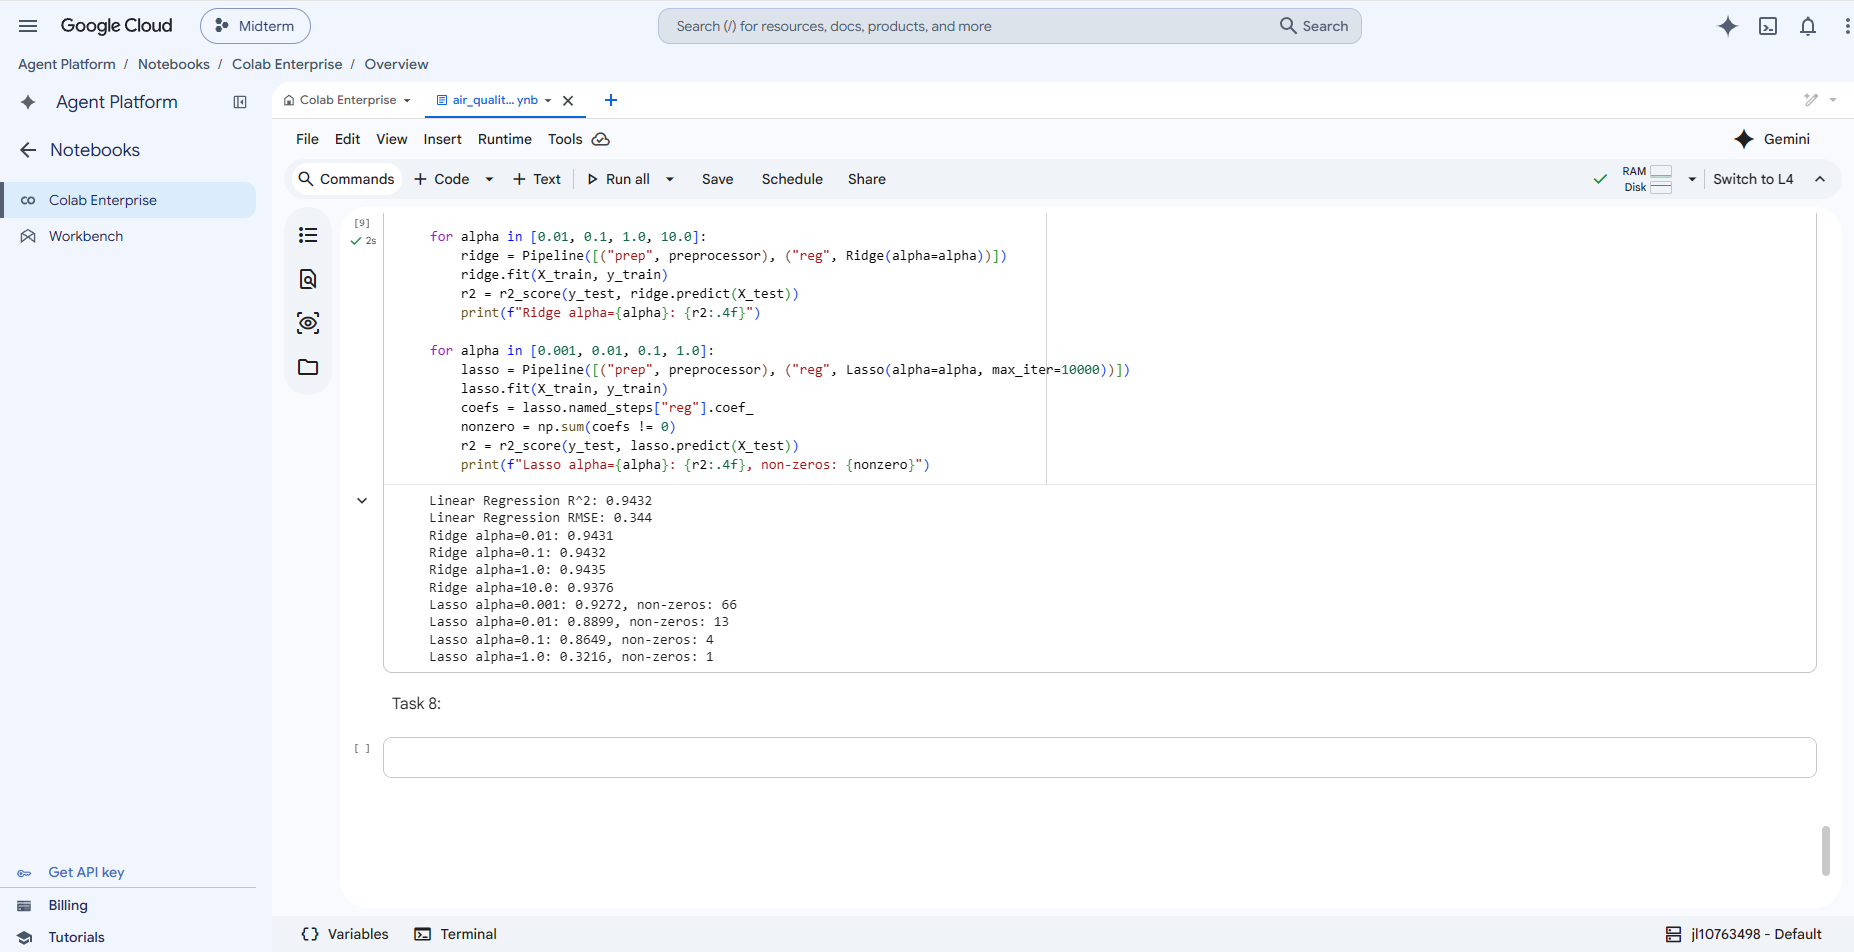

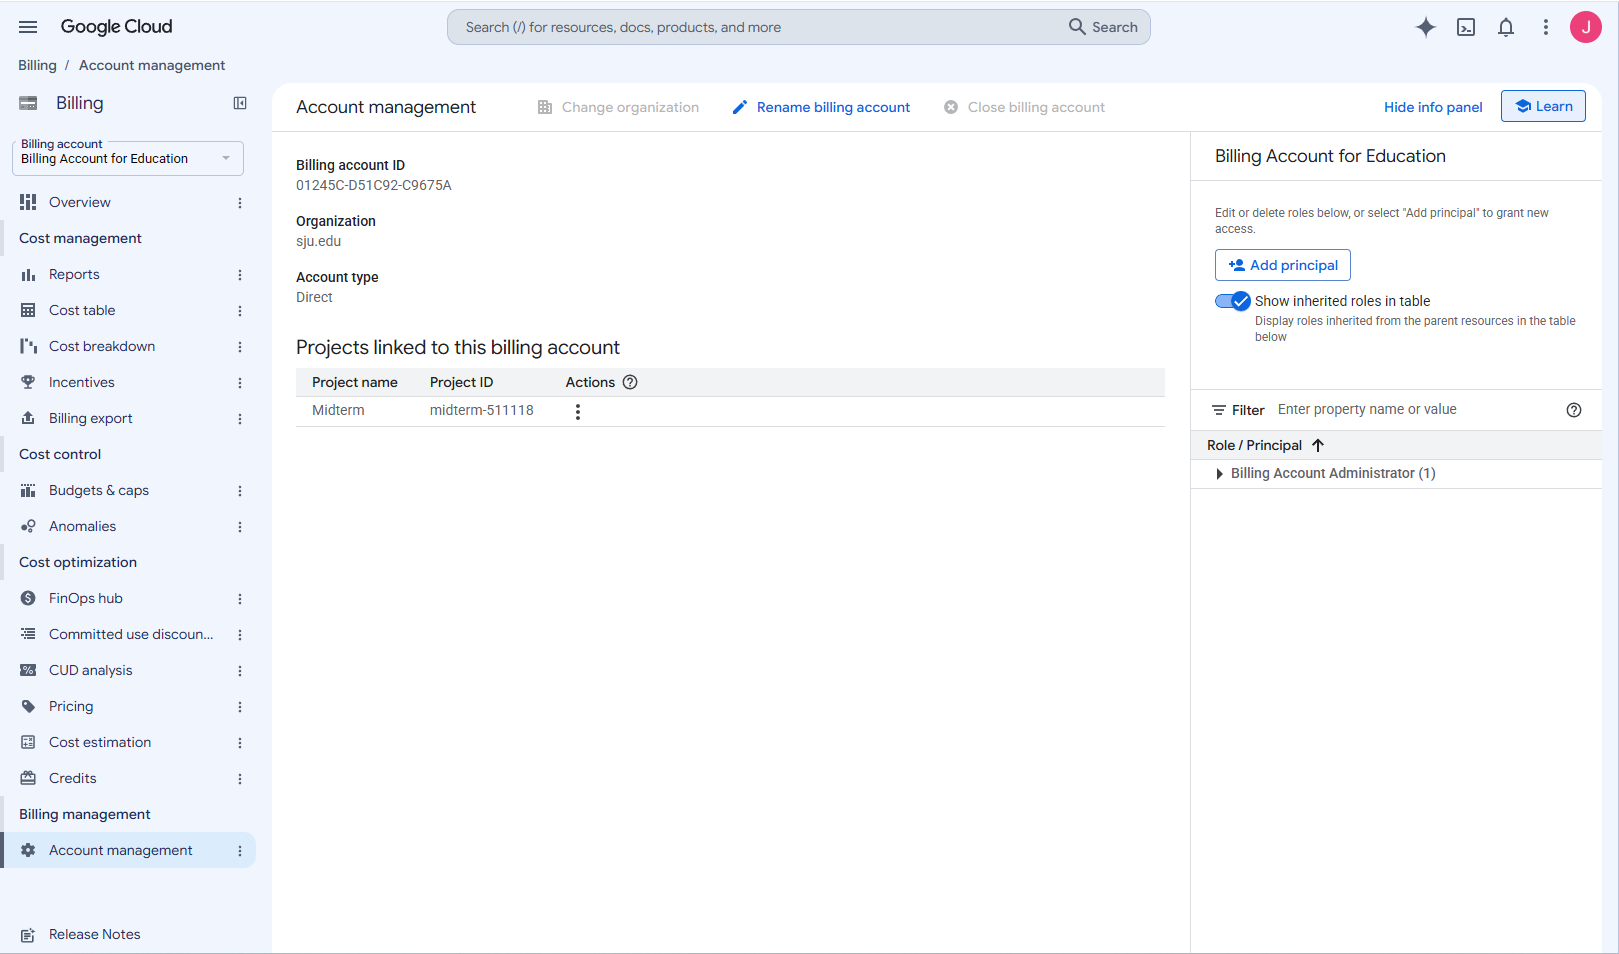

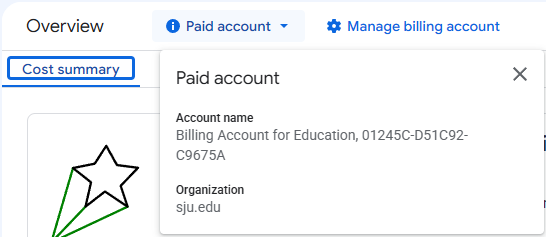